# Part VIII — The reset: past results or this weekend's pace?
**Proposal question:** *can a pre-race model predict which drivers score points (top 10) through a regulation reset, and should it rely on past results or on the current weekend's pace?*

- **H1** after a reset, weekend pace (practice, qualifying, grid) predicts better than past results
- **H2** past results regain their value as the new season progresses
- **H3** live forecasts for the remaining 2026 races are as accurate as the simulation (tested after the races)

The same logistic regression is trained with different sets of variables. Each 2014 and 2026 race is predicted by a model re-trained on everything before it (PCA and k-means included). **New variables for the reset (the 2026 power units are about 50% electric):** `pu_form` (points per car of every car with the same engine, last 5 races), `pu_works` (works or lead-partner team), `pu_change` (the team changed engine supplier this season), `prev_season_fade` (did the team fade at the end of last season? a proxy for moving resources early to the new rules; no public source gives teams' spending).
Code: `f1duel/reset.py`.

Points that changed hands over the winter: 2014 42%, 2026 34% (median of other years 21%)
Mechanical retirements: 2025 3% -> 2026 13%; 2013 6% -> 2014 13%


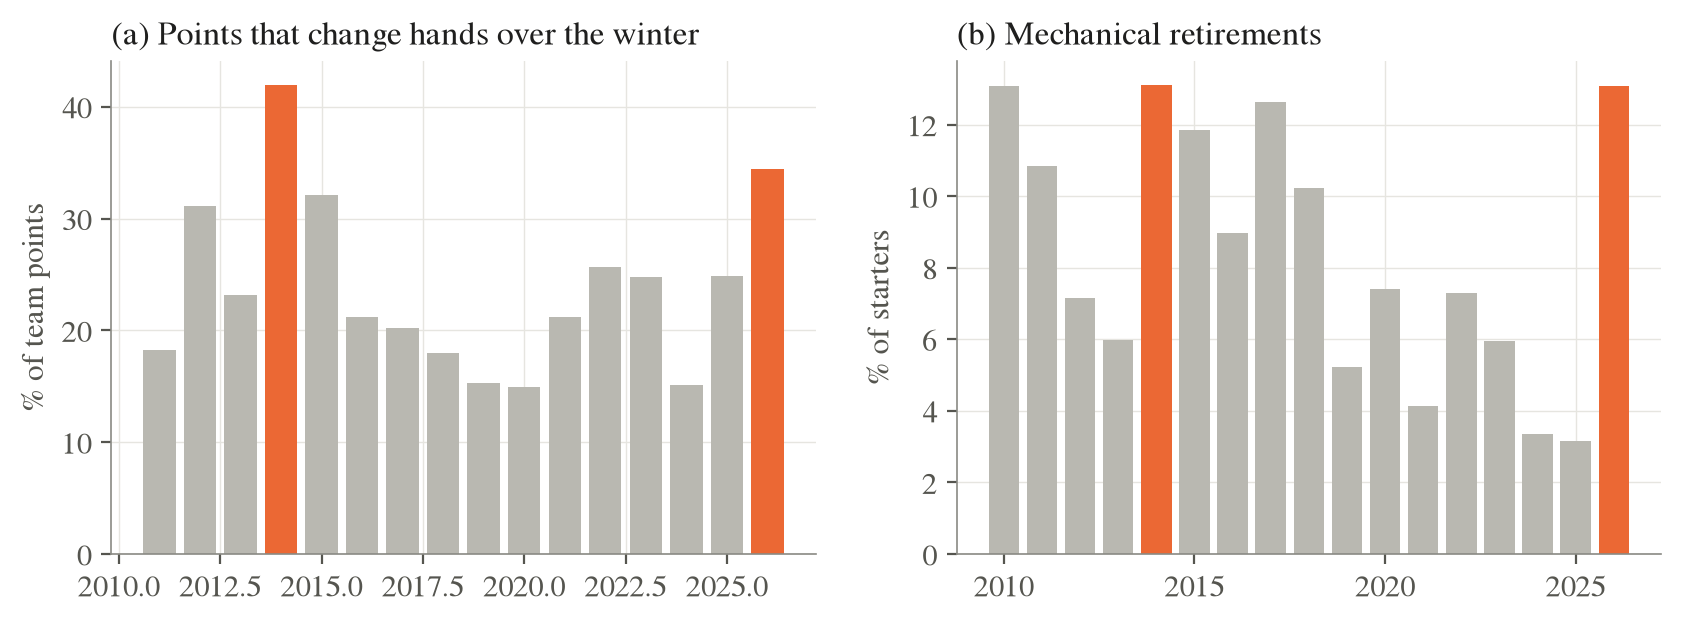

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
import json
from f1duel.reset import MODELS
R = json.load(open('../results/reset_summary.json'))
F = R['facts']
print(f"Points that changed hands over the winter: 2014 {F['points_changing_hands']['2014']:.0%}, 2026 {F['points_changing_hands']['2026']:.0%} (median of other years {np.median([v for y, v in F['points_changing_hands'].items() if y not in ('2014', '2026')]):.0%})")
print(f"Mechanical retirements: 2025 {F['mechanical_dnf_rate']['2025']:.0%} -> 2026 {F['mechanical_dnf_rate']['2026']:.0%}; 2013 {F['mechanical_dnf_rate']['2013']:.0%} -> 2014 {F['mechanical_dnf_rate']['2014']:.0%}")
from IPython.display import Image; display(Image('../figures/08_reset_facts.png', width=800))

In [2]:
rows = []
for test in ['Reset 2026', 'Reset 2014', 'Normal seasons 2020-2025']:
    for n, v in R[test]['models'].items():
        rows.append({'Test': test, 'Model': n, 'Brier rounds 1-5': v['brier_early'], 'Brier rounds 6+': v['brier_late'],
                     'Brier all': v['brier'], 'AUC': v['auc'], 'Scorers named': v['named'], 'Gain vs grid': v['gain_vs_grid'][0]})
T = pd.DataFrame(rows).set_index(['Test', 'Model']).round(4); T

Brier rounds 1-5  Brier rounds 6+  Brier all     AUC  Scorers named  Gain vs grid
Test                     Model                                                                                                        
Reset 2026               Past results only                     0.1863           0.1565     0.1649  0.8283         7.6471        0.1176
                         Past results + power unit             0.1899           0.1570     0.1663  0.8263         7.5294        0.0000
                         Grid position only                    0.1682           0.1619     0.1637  0.8294         7.5294        0.0000
                         Weekend pace only                     0.1765           0.1530     0.1596  0.8470         7.6471        0.1176
                         Full model (no power unit)            0.1723           0.1486     0.1553  0.8518         7.6471        0.1176
                         Full model                            0.1732           0.1483     0.1553  0.8509         7.6471        0.1176
                         KNN (full model)                      0.1606           0.1488     0.1521  0.8560         7.7647        0.2353
Reset 2014               Past results only                     0.1661           0.1447     0.1505  0.8523         7.7368        0.1579
                         Past results + power unit             0.1624           0.1477     0.1517  0.8507         7.6316        0.0526
                         Grid position only                    0.1545           0.1593     0.1580  0.8436         7.5789        0.0000
                         Weekend pace only                     0.1553           0.1546     0.1548  0.8572         7.5263       -0.0526
                         Full model (no power unit)            0.1475           0.1371     0.1399  0.8764         7.6842        0.1053
                         Full model                            0.1461           0.1397     0.1414  0.8730         7.5789        0.0000
                         KNN (full model)                      0.1577           0.1364     0.1422  0.8754         7.8947        0.3158
Normal seasons 2020-2025 Past results only                     0.1740           0.1746     0.1745  0.8168         7.4580       -0.2519
                         Past results + power unit             0.1748           0.1740     0.1742  0.8169         7.4351       -0.2748
                         Grid position only                    0.1635           0.1662     0.1656  0.8297         7.7099        0.0000
                         Weekend pace only                     0.1658           0.1663     0.1662  0.8374         7.7099        0.0000
                         Full model (no power unit)            0.1553           0.1547     0.1549  0.8551         7.9084        0.1985
                         Full model                            0.1556           0.1545     0.1547  0.8551         7.9160        0.2061
                         KNN (full model)                      0.1632           0.1607     0.1613  0.8433         7.8473        0.1374

Reset 2026: H1 weekend beats past early by +0.0098 Brier; H2 gap later +0.0035 (positive = weekend better); power unit changes full-model Brier by +0.0000
Reset 2014: H1 weekend beats past early by +0.0108 Brier; H2 gap later -0.0099 (positive = weekend better); power unit changes full-model Brier by +0.0015


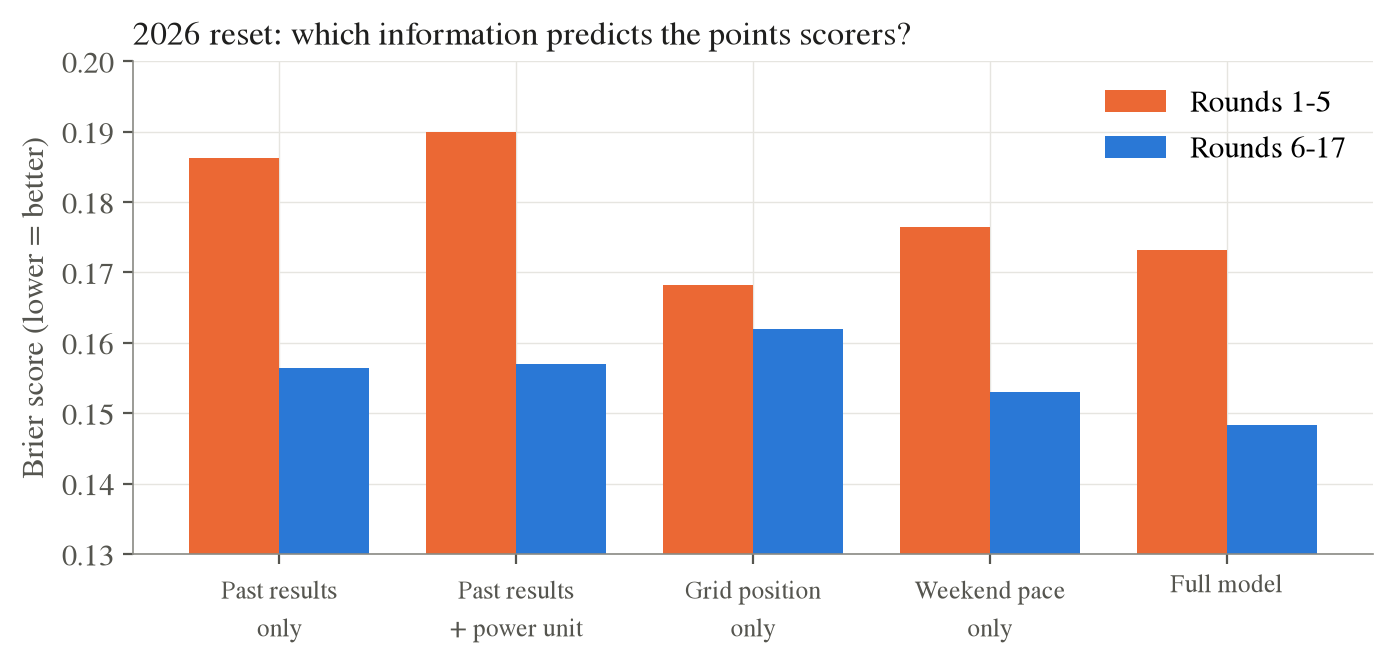

In [3]:
for test in ['Reset 2026', 'Reset 2014']:
    m = R[test]['models']
    e = m['Past results only']['brier_early'] - m['Weekend pace only']['brier_early']
    l = m['Past results only']['brier_late'] - m['Weekend pace only']['brier_late']
    pu = m['Full model']['brier'] - m['Full model (no power unit)']['brier']
    print(f"{test}: H1 weekend beats past early by {e:+.4f} Brier; H2 gap later {l:+.4f} (positive = weekend better); power unit changes full-model Brier by {pu:+.4f}")
from IPython.display import Image; display(Image('../figures/08_reset_2026_brier.png', width=700))

**Reading.** H1 holds in both resets: in the first five races, the weekend's pace predicts the points scorers better than past results. H2 holds too: the gap shrinks as the season goes on (in 2014, past results even become the better source after round 5). The full model, which combines both, is best overall. The power-unit variables do **not** improve the full model: the engine's past results are themselves "past results", which a reset makes stale; what matters is visible on Saturday.